In [57]:
%pip install pandas
%pip install numpy
%pip install matplotlib 

import matplotlib.pyplot
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [52]:
%pip install pandas
%pip install numpy
%pip install matplotlib

import pandas as pd
import numpy as np
import matplotlib as plt

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## part 1

In [27]:
import os


folder = "/Users/alessiaimpagnatiello/Downloads/data_ws2026"
frames = []
for fname in sorted(os.listdir(folder)):
    if fname.endswith(".csv"): 
        tmp = pd.read_csv(os.path.join(folder, fname))
        tmp["Ticker"] = fname.replace(".csv", "") 
        frames.append(tmp)


df = pd.concat(frames, ignore_index=True)
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date").sort_index()
df["Ticker"].value_counts()

Ticker
EXR     1002
QCOM    1002
PEP     1002
SWK     1002
LOW     1002
Name: count, dtype: int64

In [28]:
print(df.head())

               Open     High      Low    Close   Volume  Dividends  \
Date                                                                 
2022-01-03  186.093  186.241  176.428  179.724   607700        0.0   
2022-01-03  164.686  168.261  164.083  167.658  5990200        0.0   
2022-01-03  147.416  148.264  146.021  148.084  5488900        0.0   
2022-01-03  158.196  158.413  153.910  155.330   903100        0.0   
2022-01-03  234.641  235.546  229.091  231.300  5302100        0.0   

            Stock Splits Ticker  
Date                             
2022-01-03           0.0    EXR  
2022-01-03           0.0   QCOM  
2022-01-03           0.0    PEP  
2022-01-03           0.0    SWK  
2022-01-03           0.0    LOW  


In [29]:
summary = pd.DataFrame({
    "max_value": g["High"].max(),
    "max_date": g["High"].idxmax(), 
    "min_value": g["Low"].min(),
    "min_date": g["Low"].idxmin(),
})
print(summary)


        max_value   max_date  min_value   min_date
Ticker                                            
EXR       186.241 2022-01-03     88.742 2023-11-01
LOW       274.158 2024-10-15    155.134 2022-06-22
PEP       174.223 2023-05-15    120.266 2025-05-23
QCOM      219.816 2024-06-18     93.162 2022-11-03
SWK       164.178 2022-01-13     50.459 2025-04-09


In [49]:
df["Close"] =np.log(df["Close"])
print(df["Close"])
logreturns = df["Close"]

print(logreturns.min())
print(logreturns.max())
print(logreturns.mean())
print(logreturns.std())
print(logreturns.skew())
    

Date
2022-01-03   -0.695229
2022-01-03   -0.711833
2022-01-03   -0.743159
2022-01-03   -0.730840
2022-01-03   -0.639862
                ...   
2025-12-30   -0.707085
2025-12-30   -0.634077
2025-12-30   -0.784865
2025-12-30   -0.758275
2025-12-30   -0.978596
Name: Close, Length: 5010, dtype: float64
-1.143336044985902
-0.6082968037778079
-0.7764803233447717
0.10387036467126536
-0.9914372768534621


In [47]:
df["Close"].resample("ME").mean() 
df.groupby("Ticker")["Close"].resample("ME").mean()
monthly = df.groupby("Ticker")["Close"].resample("ME").mean()
monthly.groupby("Ticker").max()
monthly.groupby("Ticker").idxmax() 
monthly.unstack(level=0) 

Ticker,EXR,LOW,PEP,QCOM,SWK
Date,,,,,
2022-01-31,0.490382,0.521260,0.475869,0.484400,0.480276
2022-02-28,0.485008,0.514197,0.472738,0.481601,0.466301
2022-03-31,0.486886,0.512644,0.468189,0.468916,0.453580
2022-04-30,0.494860,0.501889,0.476223,0.455136,0.444995
2022-05-31,0.474394,0.496535,0.473777,0.452148,0.425080
2022-06-30,0.468801,0.490090,0.469867,0.447562,0.412352
2022-07-31,0.473445,0.492392,0.475528,0.457341,0.412443
2022-08-31,0.492687,0.503137,0.479976,0.461041,0.391622
2022-09-30,0.481498,0.497516,0.475280,0.441389,0.372523


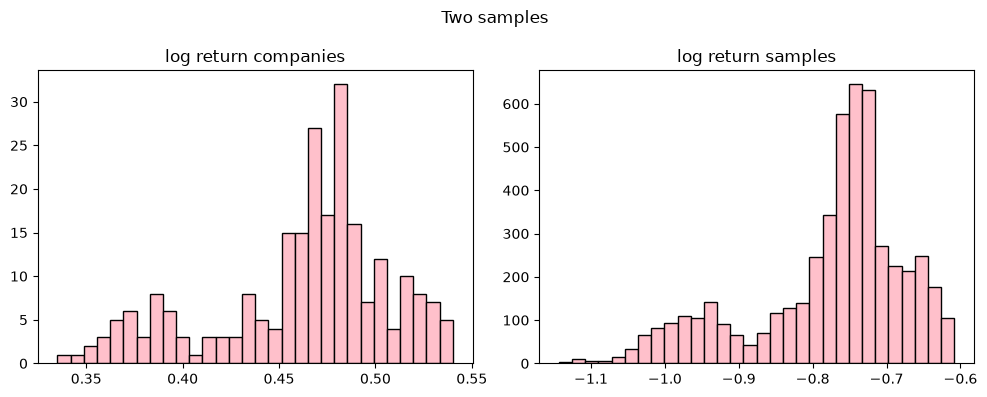

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4)) 
axes[0].hist(monthly, bins=30, color="pink", edgecolor="black")
axes[0].set_title("log return companies")
axes[1].hist(logreturns, bins=30, color="pink", edgecolor="black")
axes[1].set_title("log return samples")
fig.suptitle("Two samples")
plt.tight_layout(); plt.show()

im so sorry for this

## Pt2

In [74]:
df2 = pd.read_csv("/Users/alessiaimpagnatiello/Downloads/companies_no_subindustry.csv")
df2

,Symbol,Security,GICS_Sector,hq,included,Founded
0,MMM,3M,Industrials,"Saint Paul, Minnesota",09.08.1976,1902
1,AOS,A. O. Smith,Industrials,"Milwaukee, Wisconsin",26.07.2017,1916
2,ABT,Abbott,Health Care,"North Chicago, Illinois",31.03.1964,1888
3,ABBV,AbbVie,Health Care,"North Chicago, Illinois",31.12.2012,2013 (1888)
4,ABMD,Abiomed,Health Care,"Danvers, Massachusetts",31.05.2018,1981
...,...,...,...,...,...,...
498,YUM,Yum! Brands,Consumer Discretionary,"Louisville, Kentucky",06.10.1997,1997
499,ZBRA,Zebra Technologies,Information Technology,"Lincolnshire, Illinois",23.12.2019,1969
500,ZBH,Zimmer Biomet,Health Care,"Warsaw, Indiana",07.08.2001,1927
501,ZION,Zions Bancorporation,Financials,"Salt Lake City, Utah",22.06.2001,1873


In [84]:
mv = df2.isna()
print(mv)

df2.dropna()

     Symbol  Security  GICS_Sector     hq  included  Founded
0     False     False        False  False     False    False
1     False     False        False  False     False    False
2     False     False        False  False     False    False
3     False     False        False  False     False    False
4     False     False        False  False     False    False
..      ...       ...          ...    ...       ...      ...
498   False     False        False  False     False    False
499   False     False        False  False     False    False
500   False     False        False  False     False    False
501   False     False        False  False     False    False
502   False     False        False  False     False    False

[503 rows x 6 columns]


,Symbol,Security,GICS_Sector,hq,included,Founded
0,MMM,3M,Industrials,"Saint Paul, Minnesota",09.08.1976,1902
1,AOS,A. O. Smith,Industrials,"Milwaukee, Wisconsin",26.07.2017,1916
2,ABT,Abbott,Health Care,"North Chicago, Illinois",31.03.1964,1888
3,ABBV,AbbVie,Health Care,"North Chicago, Illinois",31.12.2012,2013 (1888)
4,ABMD,Abiomed,Health Care,"Danvers, Massachusetts",31.05.2018,1981
...,...,...,...,...,...,...
498,YUM,Yum! Brands,Consumer Discretionary,"Louisville, Kentucky",06.10.1997,1997
499,ZBRA,Zebra Technologies,Information Technology,"Lincolnshire, Illinois",23.12.2019,1969
500,ZBH,Zimmer Biomet,Health Care,"Warsaw, Indiana",07.08.2001,1927
501,ZION,Zions Bancorporation,Financials,"Salt Lake City, Utah",22.06.2001,1873


## pt 3


In [113]:
from numpy import random
import random as r
random.binomial(n=100, p=0, size=500)
random.poisson(lam=100, size=500)




array([ 99,  98, 106,  98, 116,  95,  94, 105,  97, 106, 116, 100, 104,
        70, 105,  91,  96,  91,  95,  87,  98,  78, 105,  98,  98,  92,
        95,  99,  95, 103, 104, 106, 100, 101,  96, 103, 109,  86, 101,
        75,  91, 112, 104,  99,  82, 110, 111, 104, 117, 105, 102, 104,
        99,  90,  89,  98, 109,  93,  92, 114,  97, 113, 106,  90, 113,
        89, 102, 120, 110,  74,  98,  98,  97,  90, 108, 101,  98, 118,
       108, 102,  94,  88,  97,  95, 120,  96,  98,  91,  94,  99, 111,
        82,  87, 103, 114,  96, 110, 100,  93,  93, 109, 100, 100, 109,
        99, 114,  94, 104, 102,  92,  99, 105, 104,  98,  99,  92, 110,
       100, 103, 100, 104,  96,  99, 118,  83, 102,  95, 101,  75,  96,
        80, 101,  89,  97,  87, 107,  94, 110,  99, 100, 101, 105, 108,
        97,  94,  87,  88,  98, 106,  98, 109,  97,  92, 108, 109, 118,
        95, 100, 105, 105, 101, 103, 107,  99, 100,  99, 113, 117, 120,
       105,  78,  92,  88,  97,  97, 103,  94,  90, 101,  87, 10

## I'm so sorry.